In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect("../olist.duckdb", read_only=True)
base = con.sql("""
SELECT order_id, customer_state AS uf,
       CAST(dt_compra AS DATE)  AS d_compra,
       CAST(dt_entrega AS DATE) AS d_entrega,
       prazo_prometido_dias, prazo_real_dias
FROM analitica_pedidos
""").df()
con.close()

bt = duckdb.connect()          # banco em memória, só para o backtest
bt.register("base", base)
bt.execute("""
CREATE TABLE ped AS
SELECT order_id, uf, CAST(d_compra AS DATE) AS d_compra, CAST(d_entrega AS DATE) AS d_entrega,
       prazo_prometido_dias, prazo_real_dias
FROM base
""")
bt.sql("SELECT COUNT(*) AS pedidos, MIN(d_compra) AS de, MAX(d_compra) AS ate FROM ped").df()

,pedidos,de,ate
0,96470,2016-09-15,2018-08-29


In [2]:
bt.execute("""
CREATE TABLE dias AS
SELECT CAST(t AS DATE) AS d
FROM generate_series(DATE '2017-03-01', DATE '2018-09-30', INTERVAL 1 DAY) AS g(t)
""")

bt.execute("""
CREATE TABLE janela_uf AS
SELECT e.uf, d.d, COUNT(*) AS n,
       quantile_cont(p.prazo_real_dias, 0.80) AS p80,
       quantile_cont(p.prazo_real_dias, 0.85) AS p85,
       quantile_cont(p.prazo_real_dias, 0.90) AS p90,
       quantile_cont(p.prazo_real_dias, 0.95) AS p95
FROM (SELECT DISTINCT uf FROM ped) e
CROSS JOIN dias d
JOIN ped p ON p.uf = e.uf AND p.d_entrega < d.d AND p.d_entrega >= d.d - 28
GROUP BY e.uf, d.d
""")

bt.execute("""
CREATE TABLE janela_br AS
SELECT d.d, COUNT(*) AS n,
       quantile_cont(p.prazo_real_dias, 0.80) AS p80,
       quantile_cont(p.prazo_real_dias, 0.85) AS p85,
       quantile_cont(p.prazo_real_dias, 0.90) AS p90,
       quantile_cont(p.prazo_real_dias, 0.95) AS p95
FROM dias d
JOIN ped p ON p.d_entrega < d.d AND p.d_entrega >= d.d - 28
GROUP BY d.d
""")
bt.sql("SELECT (SELECT COUNT(*) FROM janela_uf) AS linhas_uf, (SELECT COUNT(*) FROM janela_br) AS linhas_br").df()

,linhas_uf,linhas_br
0,15459,579


In [3]:
bt.execute("""
CREATE TABLE regra AS
SELECT p.order_id, p.uf, p.d_compra, p.prazo_real_dias, p.prazo_prometido_dias,
       COALESCE(CASE WHEN u.n >= 30 THEN u.p80 END, b.p80) AS p80,
       COALESCE(CASE WHEN u.n >= 30 THEN u.p85 END, b.p85) AS p85,
       COALESCE(CASE WHEN u.n >= 30 THEN u.p90 END, b.p90) AS p90,
       COALESCE(CASE WHEN u.n >= 30 THEN u.p95 END, b.p95) AS p95,
       (COALESCE(u.n, 0) >= 30) AS usou_uf
FROM ped p
LEFT JOIN janela_uf u ON u.uf = p.uf AND u.d = p.d_compra
LEFT JOIN janela_br b ON b.d = p.d_compra
WHERE p.d_compra >= DATE '2017-03-01'
""")
bt.sql("""
SELECT COUNT(*) AS pedidos_avaliados,
       SUM((p90 IS NULL)::INT) AS sem_regra,
       ROUND(100.0 * AVG(usou_uf::INT), 1) AS pct_usou_estado
FROM regra
""").df()

,pedidos_avaliados,sem_regra,pct_usou_estado
0,93800,0.0,96.5


In [9]:
chk = bt.sql("SELECT * FROM regra WHERE usou_uf ORDER BY random() LIMIT 1").df().iloc[0]
dia = str(chk["d_compra"])[:10]
manual = bt.sql(f"""
SELECT COUNT(*) AS n, quantile_cont(prazo_real_dias, 0.90) AS p90_manual,
       MAX(d_entrega) AS ultima_entrega_usada
FROM ped
WHERE uf = '{chk["uf"]}' AND d_entrega < DATE '{dia}' AND d_entrega >= DATE '{dia}' - 28
""").df().iloc[0]
print("estado:", chk["uf"], "| compra:", dia)
print("P90 da regra :", chk["p90"], "| P90 manual:", manual["p90_manual"])
print("última entrega usada:", str(manual["ultima_entrega_usada"])[:10], "(tem que ser antes da compra)")

estado: SP | compra: 2018-04-25
P90 da regra : 19.0 | P90 manual: 19.0
última entrega usada: 2018-04-24 (tem que ser antes da compra)


In [10]:
res = bt.sql("""
SELECT 'atual (Olist)' AS regra,
       ROUND(AVG(prazo_prometido_dias), 1) AS prazo_medio_prometido,
       ROUND(100.0 * AVG((prazo_real_dias > prazo_prometido_dias)::INT), 2) AS pct_atraso
FROM regra
UNION ALL SELECT 'P80 móvel', ROUND(AVG(CEIL(p80)), 1), ROUND(100.0 * AVG((prazo_real_dias > CEIL(p80))::INT), 2) FROM regra
UNION ALL SELECT 'P85 móvel', ROUND(AVG(CEIL(p85)), 1), ROUND(100.0 * AVG((prazo_real_dias > CEIL(p85))::INT), 2) FROM regra
UNION ALL SELECT 'P90 móvel', ROUND(AVG(CEIL(p90)), 1), ROUND(100.0 * AVG((prazo_real_dias > CEIL(p90))::INT), 2) FROM regra
UNION ALL SELECT 'P95 móvel', ROUND(AVG(CEIL(p95)), 1), ROUND(100.0 * AVG((prazo_real_dias > CEIL(p95))::INT), 2) FROM regra
""").df()

est = bt.sql("""
SELECT k AS dias_extra,
       ROUND(AVG(prazo_prometido_dias) + k, 1) AS prazo_medio_prometido,
       ROUND(100.0 * AVG((prazo_real_dias > prazo_prometido_dias + k)::INT), 2) AS pct_atraso
FROM regra, range(0, 13) AS t(k)
GROUP BY k ORDER BY k
""").df()
display(res)
display(est)

,regra,prazo_medio_prometido,pct_atraso
0,atual (Olist),24.0,6.89
1,P80 móvel,16.5,20.78
2,P85 móvel,18.2,16.52
3,P90 móvel,20.5,12.04
4,P95 móvel,24.8,6.97


,dias_extra,prazo_medio_prometido,pct_atraso
0,0,24.0,6.89
1,1,25.0,6.01
2,2,26.0,5.43
3,3,27.0,4.91
4,4,28.0,4.43
5,5,29.0,3.96
6,6,30.0,3.51
7,7,31.0,3.00
8,8,32.0,2.64
9,9,33.0,2.40


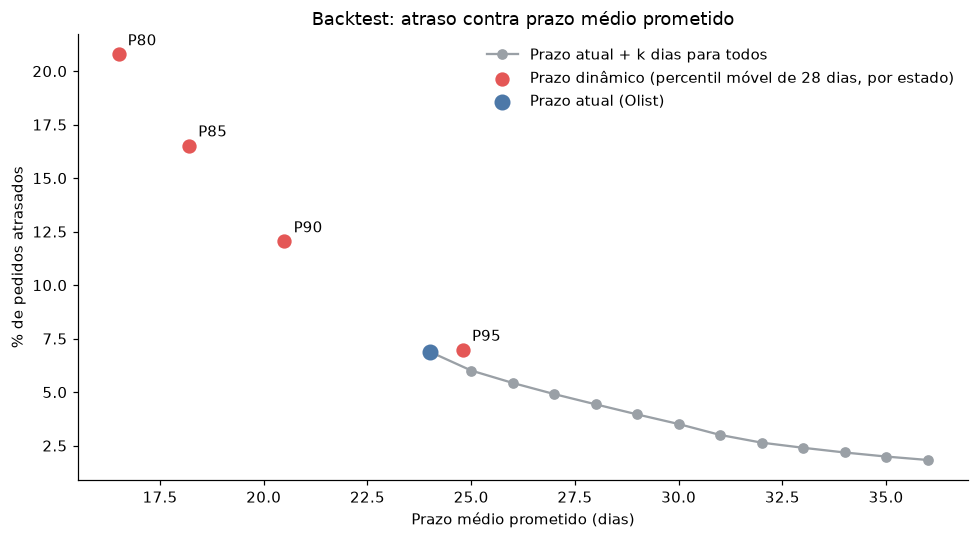

In [11]:
from pathlib import Path
Path("../images").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

din = res[res["regra"].str.startswith("P")]
atual = res[res["regra"] == "atual (Olist)"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(est["prazo_medio_prometido"], est["pct_atraso"], marker="o", color="#9AA0A6",
        label="Prazo atual + k dias para todos")
ax.scatter(din["prazo_medio_prometido"], din["pct_atraso"], color="#E45756", s=70, zorder=3,
           label="Prazo dinâmico (percentil móvel de 28 dias, por estado)")
for _, r in din.iterrows():
    ax.annotate(r["regra"].split()[0], (r["prazo_medio_prometido"], r["pct_atraso"]),
                textcoords="offset points", xytext=(6, 6))
ax.scatter(atual["prazo_medio_prometido"], atual["pct_atraso"], color="#4C78A8", s=90, zorder=3,
           label="Prazo atual (Olist)")
ax.set_xlabel("Prazo médio prometido (dias)")
ax.set_ylabel("% de pedidos atrasados")
ax.set_title("Backtest: atraso contra prazo médio prometido")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../images/05_backtest_curva.png", bbox_inches="tight")
plt.show()

,mes,pedidos_rj,atraso_atual,atraso_p90,prazo_atual,prazo_p90
0,2017-03,370,4.3,8.4,24.9,18.4
1,2017-04,325,6.5,21.5,27.0,17.8
2,2017-05,466,2.8,5.6,25.1,21.3
3,2017-06,399,3.3,9.3,25.4,20.6
4,2017-07,547,3.1,8.4,24.5,19.1
5,2017-08,537,3.0,8.8,24.6,18.7
6,2017-09,591,5.1,11.3,22.8,18.6
7,2017-10,654,6.9,11.6,23.3,19.2
8,2017-11,1012,26.0,33.9,22.8,19.7
9,2017-12,746,24.0,39.1,28.8,21.9


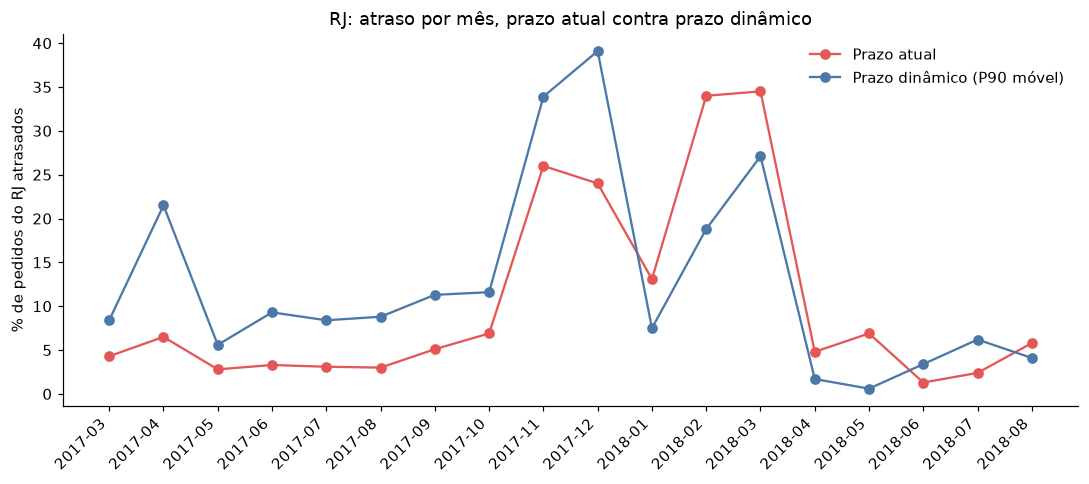

In [12]:
rj = bt.sql("""
SELECT strftime(d_compra, '%Y-%m') AS mes,
  COUNT(*) FILTER (WHERE uf = 'RJ') AS pedidos_rj,
  ROUND(100.0 * AVG((prazo_real_dias > prazo_prometido_dias)::INT) FILTER (WHERE uf = 'RJ'), 1) AS atraso_atual,
  ROUND(100.0 * AVG((prazo_real_dias > CEIL(p90))::INT) FILTER (WHERE uf = 'RJ'), 1) AS atraso_p90,
  ROUND(AVG(prazo_prometido_dias) FILTER (WHERE uf = 'RJ'), 1) AS prazo_atual,
  ROUND(AVG(CEIL(p90)) FILTER (WHERE uf = 'RJ'), 1) AS prazo_p90
FROM regra GROUP BY 1 ORDER BY 1
""").df()
display(rj)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rj["mes"], rj["atraso_atual"], marker="o", color="#E45756", label="Prazo atual")
ax.plot(rj["mes"], rj["atraso_p90"], marker="o", color="#4C78A8", label="Prazo dinâmico (P90 móvel)")
plt.xticks(rotation=45, ha="right")
ax.set_ylabel("% de pedidos do RJ atrasados")
ax.set_title("RJ: atraso por mês, prazo atual contra prazo dinâmico")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../images/06_backtest_rj.png", bbox_inches="tight")
plt.show()

,regra,prazo_medio_prometido,pct_atraso,atraso_referencia_mesmo_prazo,dinamico_menos_referencia_pp
1,P80 móvel,16.5,20.78,24.29,-3.51
2,P85 móvel,18.2,16.52,17.23,-0.71
3,P90 móvel,20.5,12.04,12.38,-0.34
4,P95 móvel,24.8,6.97,6.19,0.78


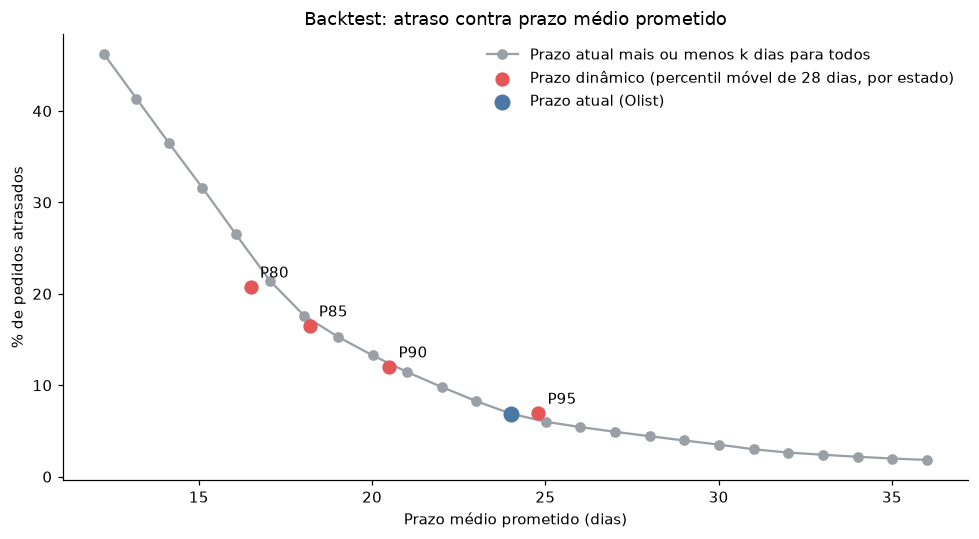

In [13]:
import numpy as np

ext = bt.sql("""
SELECT k AS dias_extra,
       ROUND(AVG(GREATEST(prazo_prometido_dias + k, 1)), 2) AS prazo_medio_prometido,
       ROUND(100.0 * AVG((prazo_real_dias > GREATEST(prazo_prometido_dias + k, 1))::INT), 2) AS pct_atraso
FROM regra, range(-12, 13) AS t(k)
GROUP BY k ORDER BY k
""").df()

dyn = res[res["regra"].str.startswith("P")].copy()
dyn["atraso_referencia_mesmo_prazo"] = np.interp(
    dyn["prazo_medio_prometido"], ext["prazo_medio_prometido"], ext["pct_atraso"]
).round(2)
dyn["dinamico_menos_referencia_pp"] = (dyn["pct_atraso"] - dyn["atraso_referencia_mesmo_prazo"]).round(2)
display(dyn)

atual = res[res["regra"] == "atual (Olist)"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ext["prazo_medio_prometido"], ext["pct_atraso"], marker="o", color="#9AA0A6",
        label="Prazo atual mais ou menos k dias para todos")
ax.scatter(dyn["prazo_medio_prometido"], dyn["pct_atraso"], color="#E45756", s=70, zorder=3,
           label="Prazo dinâmico (percentil móvel de 28 dias, por estado)")
for _, r in dyn.iterrows():
    ax.annotate(r["regra"].split()[0], (r["prazo_medio_prometido"], r["pct_atraso"]),
                textcoords="offset points", xytext=(6, 6))
ax.scatter(atual["prazo_medio_prometido"], atual["pct_atraso"], color="#4C78A8", s=90, zorder=3,
           label="Prazo atual (Olist)")
ax.set_xlabel("Prazo médio prometido (dias)")
ax.set_ylabel("% de pedidos atrasados")
ax.set_title("Backtest: atraso contra prazo médio prometido")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../images/05_backtest_curva.png", bbox_inches="tight")
plt.show()